# Next-day wildfire prediction per H3 cell (BC) with TabPFN

**Question:** will an H3 resolution-6 cell in BC have a FIRMS fire detection **tomorrow** (day *t+1*), given everything known at the end of **today** (day *t*)?

**Inputs (upload both to Colab, or put them on Google Drive):**
- `era5_h3_res6_cell_date_18_24.parquet`: ERA5 weather for every BC cell, every day, May–September 2018–2024 (30,793 cells × 1,071 days ≈ 33M rows, one row per cell-day).
- `firms_h3_res6_cell_date_18_24.parquet`: one row per cell-day **with** a thermal detection (53,953 rows). A cell-day is fire if `detection_count > 0`.

**How the join works:** ERA5 is the spine because it covers every cell and day. FIRMS is left-joined onto it, so cell-days with no detection become `fire = 0`. Joining the other way would keep only fire rows and leave the model with no negatives.

**Splits:** train 2018–2022, validate 2023 (calibration and threshold), test 2024 (used once).

**Pipeline:**
1. Load FIRMS fire events and build the H3 neighbour table.
2. For each year: weather features from ERA5, fire-history and neighbour features from FIRMS, label = fire at *t+1*.
3. Sample rows: keep every positive, keep "active" negatives (fire in the cell or nearby in the last few days), and a small random share of quiet negatives. Each row carries a weight so metrics reflect all of BC.
4. Baselines: persistence and XGBoost on GPU.
5. TabPFN on GPU: several 10k-row contexts, averaged.
6. Calibrate on 2023, report 2023 and 2024, draw maps.

**Runtime:** use a GPU runtime (*Runtime → Change runtime type → T4 GPU* or better). Building features takes a few minutes per year. Set `QUICK = True` in the config cell for a fast smoke test first.

In [7]:
# Install packages (Colab already has numpy, pandas, scikit-learn, torch, matplotlib).
%pip install -q -U "tabpfn>=2.0" h3 polars pyarrow xgboost

In [15]:
# Optional: read the parquet files from Google Drive instead of /content.
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [8]:
import math
import time
import datetime as dt
from pathlib import Path

import h3
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score

print("polars", pl.__version__, "| h3", h3.__version__)

polars 2.1.0 | h3 4.5.0


In [9]:
import torch

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU found. Switch to a GPU runtime: TabPFN on CPU is very slow.")

GPU: Tesla T4


In [17]:
# ---------------- Configuration ----------------
DATA_DIR = Path("/content/drive/MyDrive/content")                      # Point directly to the folder containing the parquet files
ERA5_PATH = DATA_DIR / "era5_h3_res6_cell_date_18_24.parquet"
FIRMS_PATH = DATA_DIR / "firms_h3_res6_cell_date_18_24.parquet"
OUT_DIR = DATA_DIR / "tabpfn_next_day_outputs"
OUT_DIR.mkdir(parents=True, exist_ok=True)

QUICK = False            # True = small, fast smoke test of the whole notebook
REBUILD = False          # True = rebuild the sampled datasets even if cached files exist
SEED = 42

TRAIN_YEARS = [2018, 2019, 2020, 2021, 2022]
VAL_YEAR = 2023
TEST_YEAR = 2024
SEASON_END = (9, 30)     # last day in the data; rows on this day have no t+1 label and are dropped

# Row sampling. "Active" = fire in this cell in the last 7 days, or in a ring-1 neighbour in
# the last 3 days, or in a ring-2 neighbour today. Positives are always kept (weight 1).
# Kept negatives get weight 1 / keep-fraction, so weighted metrics match the full BC grid.
TRAIN_ACTIVE_NEG_FRAC = 1.0
TRAIN_QUIET_NEG_FRAC = 0.002
EVAL_ACTIVE_NEG_FRAC = 0.3
EVAL_QUIET_NEG_FRAC = 0.005

# TabPFN settings
CONTEXT_ROWS = 10_000        # rows per TabPFN context (TabPFN v2 is designed for up to ~10k)
N_BAGS = 3                   # number of different contexts; predictions are averaged
POS_SHARE = 0.3              # share of each context that is positive
ACTIVE_SHARE_OF_NEG = 0.6    # share of the context's negatives drawn from active rows
TABPFN_N_ESTIMATORS = 4
PREDICT_BATCH = 20_000

if QUICK:
    TRAIN_YEARS = [2021, 2022]
    TRAIN_QUIET_NEG_FRAC = 0.001
    EVAL_ACTIVE_NEG_FRAC, EVAL_QUIET_NEG_FRAC = 0.05, 0.001
    CONTEXT_ROWS, N_BAGS, TABPFN_N_ESTIMATORS = 2_000, 1, 1

ALL_YEARS = TRAIN_YEARS + [VAL_YEAR, TEST_YEAR]
for p in (ERA5_PATH, FIRMS_PATH):
    assert p.exists(), f"Missing {p}: upload it or change DATA_DIR"

## 1. Fire events and the H3 neighbour table

`events` has one row per fire cell-day. The neighbour table lists, for every cell that ever burned, its ring-1 (6 cells) and ring-2 (12 cells) neighbours, plus the unit vector from the burning cell toward each neighbour. That vector is used with the ERA5 wind to tell whether the wind blows from a fire toward a cell.

In [18]:
def as_date(frame, column):
    # Return an expression that turns `column` into a pl.Date whatever its stored type.
    dtype = frame.collect_schema()[column]
    if dtype == pl.Date:
        return pl.col(column)
    if dtype == pl.String:
        return pl.col(column).str.to_date("%Y-%m-%d")
    return pl.col(column).cast(pl.Date)


firms = pl.scan_parquet(FIRMS_PATH)
events = (
    firms.with_columns(as_date(firms, "acq_date").alias("date"))
    .filter(pl.col("detection_count") > 0)
    .select(
        "h3_cell", "date",
        pl.col("detection_count").cast(pl.Float32),
        pl.col("frp_sum").cast(pl.Float32),
        pl.col("frp_max").cast(pl.Float32),
        pl.col("brightness_max").cast(pl.Float32),
    )
    .unique(subset=["h3_cell", "date"])
    .collect()
    .with_columns(pl.col("date").dt.year().alias("year"))
)
print(f"{events.height:,} fire cell-days in {events['h3_cell'].n_unique():,} cells")
print(events.group_by("year").len().sort("year"))

# Neighbour table: src = burning cell, h3_cell = neighbour, (ux, uy) = unit vector src -> neighbour
rows = []
for src in events["h3_cell"].unique().to_list():
    lat0, lon0 = h3.cell_to_latlng(src)
    for ring in (1, 2):
        for nbr in h3.grid_ring(src, ring):
            lat1, lon1 = h3.cell_to_latlng(nbr)
            dx = (lon1 - lon0) * math.cos(math.radians((lat0 + lat1) / 2))
            dy = lat1 - lat0
            norm = math.hypot(dx, dy) or 1.0
            rows.append((src, nbr, ring, dx / norm, dy / norm))
NBR = pl.DataFrame(rows, schema={"src": pl.String, "h3_cell": pl.String, "ring": pl.Int8,
                                 "ux": pl.Float32, "uy": pl.Float32}, orient="row")
print(f"neighbour table: {NBR.height:,} rows")

# Long-run fire frequency per cell, using only years before the row's year (no look-ahead).
fire_days_per_year = events.group_by("h3_cell", "year").len("fire_days")


def prior_fire_rate(year):
    first_year = int(events["year"].min())
    if year <= first_year:
        return None  # no earlier years: the feature is left missing (NaN) for this year
    return (
        fire_days_per_year.filter(pl.col("year") < year)
        .group_by("h3_cell")
        .agg((pl.col("fire_days").sum() / (year - first_year)).cast(pl.Float32).alias("cell_fire_rate_prev_years"))
    )


# Days to map later: the test-year days whose next day had the most fire cells.
next_day_counts = (
    events.filter(pl.col("year") == TEST_YEAR)
    .with_columns((pl.col("date") - pl.duration(days=1)).alias("date"))
    .group_by("date").len().sort("len", descending=True)
)
MAP_DATES = next_day_counts["date"].head(2).to_list()
print("map dates (t):", MAP_DATES)

53,953 fire cell-days in 6,188 cells
shape: (7, 2)
┌──────┬───────┐
│ year ┆ len   │
│ ---  ┆ ---   │
│ i32  ┆ u32   │
╞══════╪═══════╡
│ 2018 ┆ 11990 │
│ 2019 ┆ 950   │
│ 2020 ┆ 723   │
│ 2021 ┆ 7993  │
│ 2022 ┆ 2085  │
│ 2023 ┆ 21262 │
│ 2024 ┆ 8950  │
└──────┴───────┘
neighbour table: 111,384 rows
map dates (t): [datetime.date(2024, 7, 17), datetime.date(2024, 7, 18)]


## 2. Features and labels, one year at a time

Everything is built per year to keep memory low (one year is about 4.7M rows). Fire seasons don't overlap across years, so no rolling window crosses from September into the next May.

**Every feature uses day *t* or earlier.** The label is fire on day *t+1*:

| Group | Features |
|---|---|
| Weather on day *t* | temperature, dewpoint, humidity, vapour-pressure deficit, wind, precipitation, soil moisture, radiation, evaporation, snow, vegetation, elevation |
| Recent weather | precipitation over 3 and 7 days, dry days in the last 7, 3-day means of temperature, humidity and VPD |
| Place and season | cell centroid latitude/longitude, day of year |
| Fire in this cell | fire today, detections, FRP, brightness, fire days in the last 3 and 7 days, days since last fire, long-run fire rate from earlier years |
| Fire nearby | ring-1 and ring-2 neighbours burning today, ring-1 neighbours in the last 3 days, ring-1 FRP, ring-1 fires with the wind blowing toward this cell |

The FIRMS fields for day *t* (FRP, brightness) are legitimate here because the target is day *t+1*. Using them to predict day *t* would leak the label.

In [19]:
WEATHER = ["t2m_c", "d2m_c", "skt", "sp", "u10", "v10", "wind_speed", "tp_mm", "rh", "vpd_kpa",
           "swvl1", "swvl2", "swvl3", "ssrd", "ssr", "str", "slhf", "pev", "evatc", "evabs", "evavt",
           "sde", "snowc", "lai_lv", "lai_hv", "cvh", "cvl", "elev_m", "lsm"]
WEATHER_RECENT = ["tp_mm_3d", "tp_mm_7d", "dry_days_7d", "t2m_c_3d", "rh_3d", "vpd_kpa_3d"]
PLACE_TIME = ["h3_lat", "h3_lon", "doy"]
FIRE_OWN = ["fire_t", "det_t", "frp_sum_t", "frp_max_t", "bright_max_t", "fire_3d", "fire_7d",
            "frp_7d", "days_since_fire", "cell_fire_rate_prev_years"]
FIRE_NBR = ["nbr1_fire_t", "nbr2_fire_t", "nbr1_frp_t", "nbr1_fire_3d", "nbr1_upwind_t", "nbr1_wind_push_t"]
FEATURES = WEATHER + WEATHER_RECENT + PLACE_TIME + FIRE_OWN + FIRE_NBR
KEYS = ["h3_cell", "date", "year"]
print(len(FEATURES), "features")


def shift_days(frame, n_days):
    # Repeat each row for k = 0..n_days-1 with date moved forward by k days.
    # Joined on (h3_cell, date), a row at day t then sees the events of days t-k.
    offsets = pl.DataFrame({"k": list(range(n_days))}, schema={"k": pl.Int32})
    return frame.join(offsets, how="cross").with_columns(
        (pl.col("date") + pl.duration(days=pl.col("k"))).alias("date"))


def weather_for_year(year):
    era = pl.scan_parquet(ERA5_PATH)
    t = pl.col("t2m") - 273.15
    d = pl.col("d2m") - 273.15
    es = 0.6108 * (17.27 * t / (t + 237.3)).exp()                   # saturation vapour pressure, kPa
    rh = 100 * ((17.625 * d) / (243.04 + d)).exp() / ((17.625 * t) / (243.04 + t)).exp()
    frame = (
        era.filter(pl.col("year") == year)
        .with_columns(as_date(era, "valid_time").alias("date"))
        .drop([c for c in ("valid_time", "era5_lat", "era5_lon", "era5_dist_km", "month")
               if c in era.collect_schema().names()])
        .with_columns(
            t.alias("t2m_c"), d.alias("d2m_c"),
            rh.clip(0, 100).alias("rh"),
            (es * (1 - rh.clip(0, 100) / 100)).alias("vpd_kpa"),
            (pl.col("u10") ** 2 + pl.col("v10") ** 2).sqrt().alias("wind_speed"),
            (pl.col("tp") * 1000).alias("tp_mm"),
            (pl.col("z") / 9.80665).alias("elev_m"),
            pl.col("date").dt.ordinal_day().alias("doy"),
        )
        .drop(["t2m", "d2m", "tp", "z"])
        .sort(["h3_cell", "date"])
        .with_columns(
            pl.col("tp_mm").rolling_sum(3, min_samples=1).over("h3_cell").alias("tp_mm_3d"),
            pl.col("tp_mm").rolling_sum(7, min_samples=1).over("h3_cell").alias("tp_mm_7d"),
            (pl.col("tp_mm") < 1.0).cast(pl.Int8).rolling_sum(7, min_samples=1).over("h3_cell").alias("dry_days_7d"),
            pl.col("t2m_c").rolling_mean(3, min_samples=1).over("h3_cell").alias("t2m_c_3d"),
            pl.col("rh").rolling_mean(3, min_samples=1).over("h3_cell").alias("rh_3d"),
            pl.col("vpd_kpa").rolling_mean(3, min_samples=1).over("h3_cell").alias("vpd_kpa_3d"),
        )
        .collect()
    )
    return frame


def fire_features(ev, wind):
    # ev: fire events of one year. wind: (h3_cell, date, u10, v10) for that year.
    today = ev.select(
        "h3_cell", "date",
        pl.lit(1, pl.Int8).alias("fire_t"),
        pl.col("detection_count").alias("det_t"),
        pl.col("frp_sum").alias("frp_sum_t"),
        pl.col("frp_max").alias("frp_max_t"),
        pl.col("brightness_max").alias("bright_max_t"),
    )
    own = (
        shift_days(ev.select("h3_cell", "date", "frp_sum"), 31)
        .group_by("h3_cell", "date")
        .agg(
            (pl.col("k") < 3).sum().cast(pl.Int16).alias("fire_3d"),
            (pl.col("k") < 7).sum().cast(pl.Int16).alias("fire_7d"),
            pl.col("frp_sum").filter(pl.col("k") < 7).sum().cast(pl.Float32).alias("frp_7d"),
            pl.col("k").min().cast(pl.Int16).alias("days_since_fire"),
        )
    )
    near = (
        ev.select(pl.col("h3_cell").alias("src"), "date", "frp_sum")
        .join(NBR, on="src")
        .join(wind.rename({"h3_cell": "src"}), on=["src", "date"], how="left")
        .with_columns((pl.col("u10") ** 2 + pl.col("v10") ** 2).sqrt().alias("speed"))
        .with_columns(
            pl.when(pl.col("speed") > 0)
            .then((pl.col("u10") * pl.col("ux") + pl.col("v10") * pl.col("uy")) / pl.col("speed"))
            .otherwise(0.0)
            .alias("align"))  # +1 = wind blows straight from the burning cell toward this cell
    )
    ring1 = pl.col("ring") == 1
    near_today = near.group_by("h3_cell", "date").agg(
        ring1.sum().cast(pl.Int16).alias("nbr1_fire_t"),
        (pl.col("ring") == 2).sum().cast(pl.Int16).alias("nbr2_fire_t"),
        pl.col("frp_sum").filter(ring1).sum().cast(pl.Float32).alias("nbr1_frp_t"),
        (ring1 & (pl.col("align") > 0.5)).sum().cast(pl.Int16).alias("nbr1_upwind_t"),
        (pl.col("align").clip(lower_bound=0) * pl.col("speed")).filter(ring1).sum().cast(pl.Float32)
        .alias("nbr1_wind_push_t"),
    )
    near_3d = (
        shift_days(near.filter(ring1).select("h3_cell", "date"), 3)
        .group_by("h3_cell", "date").agg(pl.len().cast(pl.Int16).alias("nbr1_fire_3d"))
    )
    return today, own, near_today, near_3d


def build_year(year):
    # Full feature table for every cell-day of `year`, with the next-day label `y`.
    weather = weather_for_year(year)
    ev = events.filter(pl.col("year") == year).drop("year")
    today, own, near_today, near_3d = fire_features(ev, weather.select("h3_cell", "date", "u10", "v10"))
    label = ev.select("h3_cell", (pl.col("date") - pl.duration(days=1)).alias("date"), pl.lit(1, pl.Int8).alias("y"))

    frame = weather
    for part in (today, own, near_today, near_3d, label):
        frame = frame.join(part, on=["h3_cell", "date"], how="left")
    zero_fill = [c for c in FIRE_OWN + FIRE_NBR + ["y"] if c not in ("days_since_fire", "cell_fire_rate_prev_years")]
    frame = frame.with_columns(
        [pl.col(c).fill_null(0) for c in zero_fill]
        + [pl.col("days_since_fire").fill_null(31)]
    )
    prior = prior_fire_rate(year)
    if prior is None:
        frame = frame.with_columns(pl.lit(None, pl.Float32).alias("cell_fire_rate_prev_years"))
    else:
        frame = frame.join(prior, on="h3_cell", how="left").with_columns(
            pl.col("cell_fire_rate_prev_years").fill_null(0.0))

    last_day = dt.date(year, *SEASON_END)
    frame = frame.filter(pl.col("date") < last_day)  # no t+1 label on the last day of the season
    active = (pl.col("fire_7d") > 0) | (pl.col("nbr1_fire_3d") > 0) | (pl.col("nbr2_fire_t") > 0)
    return frame.with_columns(pl.col("year").cast(pl.Int16), active.alias("active"))


def sample_rows(frame, active_frac, quiet_frac, seed):
    # Keep all positives; keep negatives with the given probabilities; weight = 1 / probability.
    rng = np.random.default_rng(seed)
    u = pl.Series("u", rng.random(frame.height))
    keep_prob = (pl.when(pl.col("y") == 1).then(1.0)
                 .when(pl.col("active")).then(active_frac)
                 .otherwise(quiet_frac))
    out = (frame.with_columns(u, keep_prob.alias("keep_prob"))
           .filter(pl.col("u") < pl.col("keep_prob"))
           .with_columns((1.0 / pl.col("keep_prob")).cast(pl.Float32).alias("weight"))
           .drop("u", "keep_prob"))
    return out.select(KEYS + FEATURES + ["active", "y", "weight"])

54 features


In [20]:
def split_of(year):
    return "train" if year in TRAIN_YEARS else ("val" if year == VAL_YEAR else "test")


cache = {s: OUT_DIR / f"{s}_rows{'_quick' if QUICK else ''}.parquet" for s in ("train", "val", "test", "map")}
if not REBUILD and all(p.exists() for p in cache.values()):
    parts = {s: pl.read_parquet(p) for s, p in cache.items()}
    print("Loaded cached datasets from", OUT_DIR)
else:
    parts = {s: [] for s in cache}
    totals = []
    for year in ALL_YEARS:
        t0 = time.time()
        full = build_year(year)
        split = split_of(year)
        if split == "train":
            sample = sample_rows(full, TRAIN_ACTIVE_NEG_FRAC, TRAIN_QUIET_NEG_FRAC, SEED + year)
        else:
            sample = sample_rows(full, EVAL_ACTIVE_NEG_FRAC, EVAL_QUIET_NEG_FRAC, SEED + year)
        parts[split].append(sample)
        if year == TEST_YEAR:  # keep every cell for the map days
            parts["map"].append(full.filter(pl.col("date").is_in(MAP_DATES))
                                .with_columns(pl.lit(1.0, pl.Float32).alias("weight"))
                                .select(KEYS + FEATURES + ["active", "y", "weight"]))
        totals.append({"year": year, "split": split, "rows": full.height, "positives": int(full["y"].sum()),
                       "active_rows": int(full["active"].sum()), "kept_rows": sample.height,
                       "seconds": round(time.time() - t0, 1)})
        print(totals[-1])
        del full
    parts = {s: pl.concat(v) for s, v in parts.items()}
    for s, p in cache.items():
        parts[s].write_parquet(p)
    pd.DataFrame(totals).to_csv(OUT_DIR / "year_totals.csv", index=False)

for s, f in parts.items():
    print(f"{s:5s}: {f.height:>9,} rows | positives {int(f['y'].sum()):>6,} | "
          f"weighted base rate {float((f['y'] * f['weight']).sum() / f['weight'].sum()):.5f}")

{'year': 2018, 'split': 'train', 'rows': 4680536, 'positives': 11979, 'active_rows': 115193, 'kept_rows': 125333, 'seconds': 14.6}
{'year': 2019, 'split': 'train', 'rows': 4680536, 'positives': 949, 'active_rows': 21599, 'kept_rows': 31204, 'seconds': 5.4}
{'year': 2020, 'split': 'train', 'rows': 4680536, 'positives': 722, 'active_rows': 16408, 'kept_rows': 26035, 'seconds': 5.7}
{'year': 2021, 'split': 'train', 'rows': 4680536, 'positives': 7989, 'active_rows': 89519, 'kept_rows': 99464, 'seconds': 6.2}
{'year': 2022, 'split': 'train', 'rows': 4680536, 'positives': 2082, 'active_rows': 35346, 'kept_rows': 45096, 'seconds': 5.6}
{'year': 2023, 'split': 'val', 'rows': 4680536, 'positives': 21259, 'active_rows': 200043, 'kept_rows': 98067, 'seconds': 5.6}
{'year': 2024, 'split': 'test', 'rows': 4680536, 'positives': 8950, 'active_rows': 88792, 'kept_rows': 56061, 'seconds': 7.7}
train:   327,132 rows | positives 23,721 | weighted base rate 0.00101
val  :    98,067 rows | positives 21,259

In [21]:
# Sanity checks on the label and on look-ahead.
check = parts["val"].sample(n=min(3000, parts["val"].height), seed=SEED).select("h3_cell", "date", "y", "fire_t")
fire_set = events.select("h3_cell", "date").with_columns(pl.lit(1, pl.Int8).alias("is_fire"))
c = (check
     .join(fire_set, on=["h3_cell", "date"], how="left")
     .join(fire_set.with_columns((pl.col("date") - pl.duration(days=1)).alias("date"))
           .rename({"is_fire": "is_fire_next"}), on=["h3_cell", "date"], how="left")
     .with_columns(pl.col("is_fire", "is_fire_next").fill_null(0)))
assert (c["fire_t"] == c["is_fire"]).all(), "fire_t does not match FIRMS on day t"
assert (c["y"] == c["is_fire_next"]).all(), "y does not match FIRMS on day t+1"
print("label checks passed: fire_t = FIRMS on day t, y = FIRMS on day t+1")

# How much of tomorrow's fire is new ignition (no fire in or near the cell recently)?
pos = parts["val"].filter(pl.col("y") == 1)
print(f"2023 positives with recent fire in or near the cell: {pos['active'].mean():.1%}")
print(f"2023 positives with no recent fire nearby (new ignitions): {1 - pos['active'].mean():.1%}")

label checks passed: fire_t = FIRMS on day t, y = FIRMS on day t+1
2023 positives with recent fire in or near the cell: 94.0%
2023 positives with no recent fire nearby (new ignitions): 6.0%


## 3. Metrics and baselines

Fire is rare (well under 1% of cell-days), so accuracy is meaningless. The main metric is **average precision (PR-AUC)**, weighted by the sampling weights so it reflects the full BC grid. Also reported: ROC-AUC, Brier score, and precision / recall / F1 at a threshold chosen on 2023 and applied unchanged to 2024.

**Persistence** ("a cell burning today burns tomorrow", with neighbour fire as a tie-breaker) is the baseline to beat. If a model can't beat it, it isn't learning anything beyond fire history.

In [22]:
def to_xy(frame):
    X = frame.select(FEATURES).to_numpy().astype(np.float32)
    return X, frame["y"].to_numpy().astype(np.int8), frame["weight"].to_numpy().astype(np.float64)


X_tr, y_tr, w_tr = to_xy(parts["train"])
X_va, y_va, w_va = to_xy(parts["val"])
X_te, y_te, w_te = to_xy(parts["test"])
X_map, y_map, _ = to_xy(parts["map"])
a_tr, a_va, a_te, a_map = (parts[s]["active"].to_numpy() for s in ("train", "val", "test", "map"))
print(X_tr.shape, X_va.shape, X_te.shape, X_map.shape)


def odds_correction(used_idx):
    # The rows a model learns from over-represent positives, and do so differently for active and
    # quiet rows (quiet negatives are kept at TRAIN_QUIET_NEG_FRAC, quiet positives at 100%).
    # For each stratum s, a_s / b_s = share of the population's positives / negatives that the model
    # saw. Multiplying the model's odds by b_s / a_s undoes the sampling exactly, stratum by stratum.
    used = np.zeros(len(y_tr), dtype=bool)
    used[used_idx] = True
    factor = {}
    for stratum in (True, False):
        s = a_tr == stratum
        a = used[s & (y_tr == 1)].sum() / max(w_tr[s & (y_tr == 1)].sum(), 1e-9)
        b = used[s & (y_tr == 0)].sum() / max(w_tr[s & (y_tr == 0)].sum(), 1e-9)
        factor[stratum] = b / max(a, 1e-12)
    return factor


def apply_correction(p, active, factor):
    p = np.clip(p, 1e-7, 1 - 1e-7)
    odds = p / (1 - p) * np.where(active, factor[True], factor[False])
    return odds / (1 + odds)


def best_f1_threshold(y, p, w):
    prec, rec, thr = precision_recall_curve(y, p, sample_weight=w)
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    i = int(np.nanargmax(f1[:-1]))
    return float(thr[i])


def scores(model, split, y, p, w, threshold):
    pred = p >= threshold
    tp = float(np.sum(w * (pred & (y == 1))))
    fp = float(np.sum(w * (pred & (y == 0))))
    fn = float(np.sum(w * (~pred & (y == 1))))
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    return {
        "model": model, "split": split,
        "pr_auc": average_precision_score(y, p, sample_weight=w),
        "roc_auc": roc_auc_score(y, p, sample_weight=w),
        "brier": float(np.average((p - y) ** 2, weights=w)),
        "threshold": threshold, "precision": precision, "recall": recall,
        "f1": 2 * precision * recall / (precision + recall) if precision + recall else 0.0,
        "base_rate": float(np.average(y, weights=w)),
    }


RESULTS = []
PRED = {}   # model -> {"val": p, "test": p, "map": p}


def report(model, p_val, p_test, p_map=None, calibrate=True):
    # Calibrate on 2023 (isotonic, weighted), pick the F1 threshold on 2023, apply both to 2024.
    if calibrate:
        iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(p_val, y_va, sample_weight=w_va)
        cal = lambda p: iso.predict(p)  # noqa: E731
    else:
        cal = lambda p: p  # noqa: E731
    pv, pt = cal(p_val), cal(p_test)
    thr = best_f1_threshold(y_va, pv, w_va)
    RESULTS.extend([scores(model, "val_2023", y_va, pv, w_va, thr),
                    scores(model, "test_2024", y_te, pt, w_te, thr)])
    PRED[model] = {"val": pv, "test": pt, "map": None if p_map is None else cal(p_map)}
    return pd.DataFrame(RESULTS[-2:]).round(4)


def persistence(X):
    col = {f: i for i, f in enumerate(FEATURES)}
    return (100 * X[:, col["fire_t"]] + 10 * X[:, col["nbr1_fire_t"]] + X[:, col["fire_7d"]]
            + 0.1 * X[:, col["nbr2_fire_t"]]).astype(np.float64)


report("persistence", persistence(X_va), persistence(X_te), persistence(X_map))

(327132, 54) (98067, 54) (56061, 54) (61586, 54)


,model,split,pr_auc,roc_auc,brier,threshold,precision,recall,f1,base_rate
0,persistence,val_2023,0.5156,0.9617,0.0026,0.4008,0.6259,0.6302,0.6280,0.0045
1,persistence,test_2024,0.4710,0.9403,0.0012,0.4008,0.5832,0.5810,0.5821,0.0019


In [23]:
# XGBoost on GPU: a strong, fast baseline that can use the whole training sample.
import xgboost as xgb

xgb_model = xgb.XGBClassifier(
    n_estimators=3000, learning_rate=0.03, max_depth=8, min_child_weight=5,
    subsample=0.8, colsample_bytree=0.8, tree_method="hist", device=DEVICE,
    eval_metric="aucpr", early_stopping_rounds=150, random_state=SEED,
)
t0 = time.time()
xgb_model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], sample_weight_eval_set=[w_va], verbose=250)
print(f"XGBoost trained in {time.time() - t0:.0f}s, best iteration {xgb_model.best_iteration}")
xgb_factor = odds_correction(np.arange(len(y_tr)))
print("odds correction (active, quiet):", {k: round(v, 5) for k, v in xgb_factor.items()})
report("xgboost",
       apply_correction(xgb_model.predict_proba(X_va)[:, 1], a_va, xgb_factor),
       apply_correction(xgb_model.predict_proba(X_te)[:, 1], a_te, xgb_factor),
       apply_correction(xgb_model.predict_proba(X_map)[:, 1], a_map, xgb_factor))

[0]	validation_0-aucpr:0.49811
[165]	validation_0-aucpr:0.36848
XGBoost trained in 4s, best iteration 15
odds correction (active, quiet): {True: np.float64(1.0), False: np.float64(0.002)}


/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [06:47:35] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


,model,split,pr_auc,roc_auc,brier,threshold,precision,recall,f1,base_rate
0,xgboost,val_2023,0.6167,0.9837,0.0024,0.3147,0.5839,0.6647,0.6217,0.0045
1,xgboost,test_2024,0.5402,0.9830,0.0012,0.3147,0.5562,0.5826,0.5691,0.0019


## 4. TabPFN on GPU

TabPFN is an in-context model: the "training set" is a context of rows passed in at prediction time, so it can't take the whole 2018–2022 sample. Each bag draws a context of `CONTEXT_ROWS` rows from the training sample:
- `POS_SHARE` positives,
- negatives split between active rows (fire in or near the cell recently, the hard cases) and quiet rows.

Bags use different random contexts, and their predictions are averaged. A context over-represents fire, and does so differently for active and quiet rows, so each bag's scores get an exact odds correction for each stratum (`odds_correction`) before averaging. The isotonic calibration on 2023 then turns them into probabilities. XGBoost gets the same correction.

If the model download asks for a Hugging Face login or licence acceptance, follow the printed instructions (`from huggingface_hub import login; login()`), then rerun this cell.

In [26]:
from tabpfn import TabPFNClassifier

train_pd = parts["train"].select(FEATURES + ["active", "y"]).to_pandas()
pos_idx = np.flatnonzero(train_pd["y"].to_numpy() == 1)
act_idx = np.flatnonzero((train_pd["y"].to_numpy() == 0) & train_pd["active"].to_numpy())
quiet_idx = np.flatnonzero((train_pd["y"].to_numpy() == 0) & ~train_pd["active"].to_numpy())
print(f"training pool: {len(pos_idx):,} positives, {len(act_idx):,} active negatives, {len(quiet_idx):,} quiet negatives")


def draw_context(rng):
    n_pos = min(len(pos_idx), int(CONTEXT_ROWS * POS_SHARE))
    n_neg = CONTEXT_ROWS - n_pos
    n_act = min(len(act_idx), int(n_neg * ACTIVE_SHARE_OF_NEG))
    n_quiet = min(len(quiet_idx), n_neg - n_act)
    idx = np.concatenate([rng.choice(pos_idx, n_pos, replace=False),
                          rng.choice(act_idx, n_act, replace=False),
                          rng.choice(quiet_idx, n_quiet, replace=False)])
    return idx


def predict_in_batches(clf, X, label):
    out = np.empty(len(X), dtype=np.float32)
    t0 = time.time()
    for start in range(0, len(X), PREDICT_BATCH):
        out[start:start + PREDICT_BATCH] = clf.predict_proba(X[start:start + PREDICT_BATCH])[:, 1]
        if start == 0:
            per_row = (time.time() - t0) / min(PREDICT_BATCH, len(X))
            print(f"    {label}: ~{per_row * len(X) / 60:.1f} min for {len(X):,} rows")
    return out


X_eval = np.vstack([X_va, X_te, X_map])
a_eval = np.concatenate([a_va, a_te, a_map])
p_eval = np.zeros(len(X_eval), dtype=np.float64)
rng = np.random.default_rng(SEED)
for bag in range(N_BAGS):
    idx = draw_context(rng)
    Xc, yc = X_tr[idx], y_tr[idx]
    clf = TabPFNClassifier(device=DEVICE, n_estimators=TABPFN_N_ESTIMATORS, random_state=SEED + bag,
                           ignore_pretraining_limits=CONTEXT_ROWS > 10_000)
    t0 = time.time()
    clf.fit(Xc, yc)
    print(f"bag {bag + 1}/{N_BAGS}: context {len(yc):,} rows ({yc.mean():.0%} positive)")
    raw = predict_in_batches(clf, X_eval, "predicting val + test + map rows")
    p_eval += apply_correction(raw, a_eval, odds_correction(idx)) / N_BAGS
    print(f"    done in {time.time() - t0:.0f}s")
    del clf
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

n_va, n_te = len(X_va), len(X_te)
report("tabpfn", p_eval[:n_va], p_eval[n_va:n_va + n_te], p_eval[n_va + n_te:])

training pool: 23,721 positives, 257,093 active negatives, 46,318 quiet negatives


tabpfn-v3.5-20260909.safetensors: reconstructing file:   0%|          |  0.00B /  876MB            

tabpfn-v3.5-20260909.safetensors: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/36.0 [00:00<?, ?B/s]

bag 1/3: context 10,000 rows (30% positive)
    predicting val + test + map rows: ~4.5 min for 215,714 rows
    done in 281s
bag 2/3: context 10,000 rows (30% positive)
    predicting val + test + map rows: ~4.6 min for 215,714 rows
    done in 275s
bag 3/3: context 10,000 rows (30% positive)
    predicting val + test + map rows: ~4.5 min for 215,714 rows
    done in 272s


,model,split,pr_auc,roc_auc,brier,threshold,precision,recall,f1,base_rate
0,tabpfn,val_2023,0.6413,0.9873,0.0024,0.3269,0.6251,0.6447,0.6348,0.0045
1,tabpfn,test_2024,0.5456,0.9872,0.0012,0.3269,0.5779,0.5829,0.5804,0.0019


## 5. Results

In [27]:
results = pd.DataFrame(RESULTS)
results.to_csv(OUT_DIR / "results.csv", index=False)
print("Weighted to the full BC grid. Threshold = best F1 on 2023, applied unchanged to 2024.")
results.round(4)

Weighted to the full BC grid. Threshold = best F1 on 2023, applied unchanged to 2024.


,model,split,pr_auc,roc_auc,brier,threshold,precision,recall,f1,base_rate
0,persistence,val_2023,0.5156,0.9617,0.0026,0.4008,0.6259,0.6302,0.6280,0.0045
1,persistence,test_2024,0.4710,0.9403,0.0012,0.4008,0.5832,0.5810,0.5821,0.0019
2,xgboost,val_2023,0.6167,0.9837,0.0024,0.3147,0.5839,0.6647,0.6217,0.0045
3,xgboost,test_2024,0.5402,0.9830,0.0012,0.3147,0.5562,0.5826,0.5691,0.0019
4,tabpfn,val_2023,0.6413,0.9873,0.0024,0.3269,0.6251,0.6447,0.6348,0.0045
5,tabpfn,test_2024,0.5456,0.9872,0.0012,0.3269,0.5779,0.5829,0.5804,0.0019


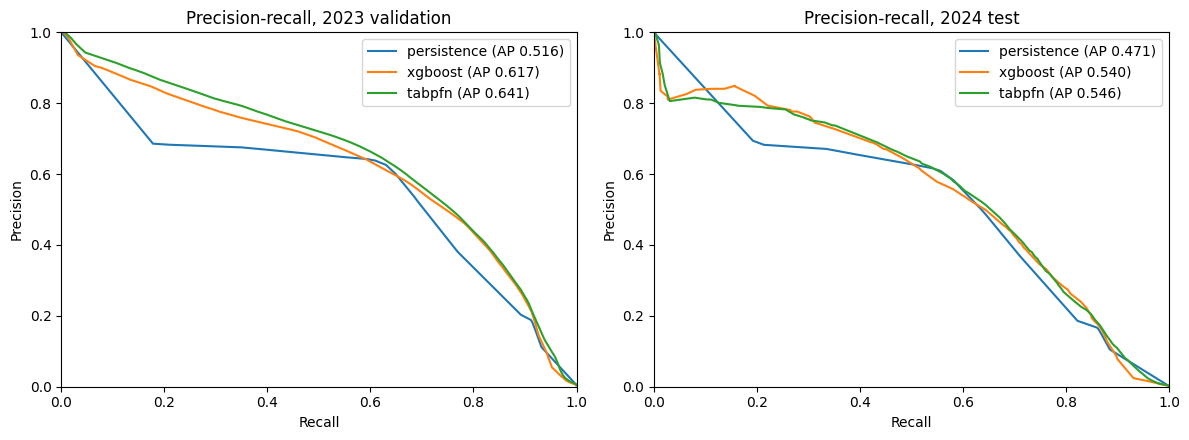

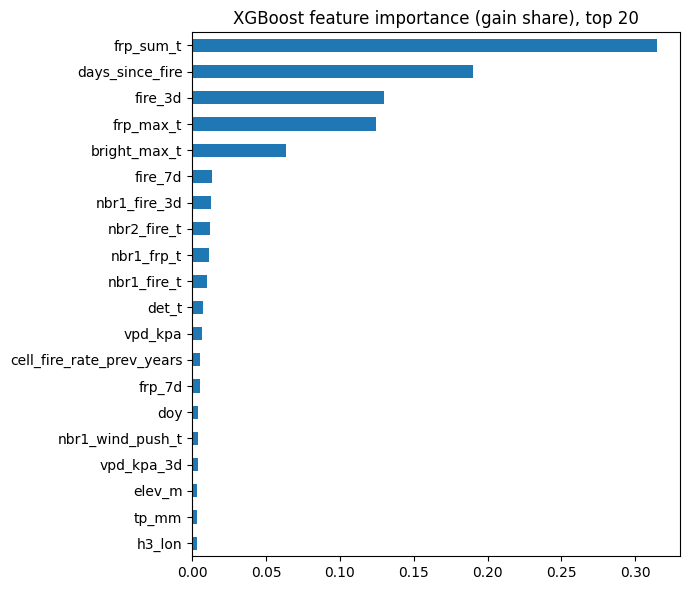

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (split, y, w) in zip(axes, [("val", y_va, w_va), ("test", y_te, w_te)]):
    for model, preds in PRED.items():
        prec, rec, _ = precision_recall_curve(y, preds[split], sample_weight=w)
        ap = average_precision_score(y, preds[split], sample_weight=w)
        ax.plot(rec, prec, label=f"{model} (AP {ap:.3f})")
    ax.set(title=f"Precision-recall, {'2023 validation' if split == 'val' else '2024 test'}",
           xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1))
    ax.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / "pr_curves.png", dpi=150)
plt.show()

importance = pd.Series(xgb_model.feature_importances_, index=FEATURES).sort_values().tail(20)
importance.plot.barh(figsize=(7, 6), title="XGBoost feature importance (gain share), top 20")
plt.tight_layout()
plt.savefig(OUT_DIR / "xgb_feature_importance.png", dpi=150)
plt.show()

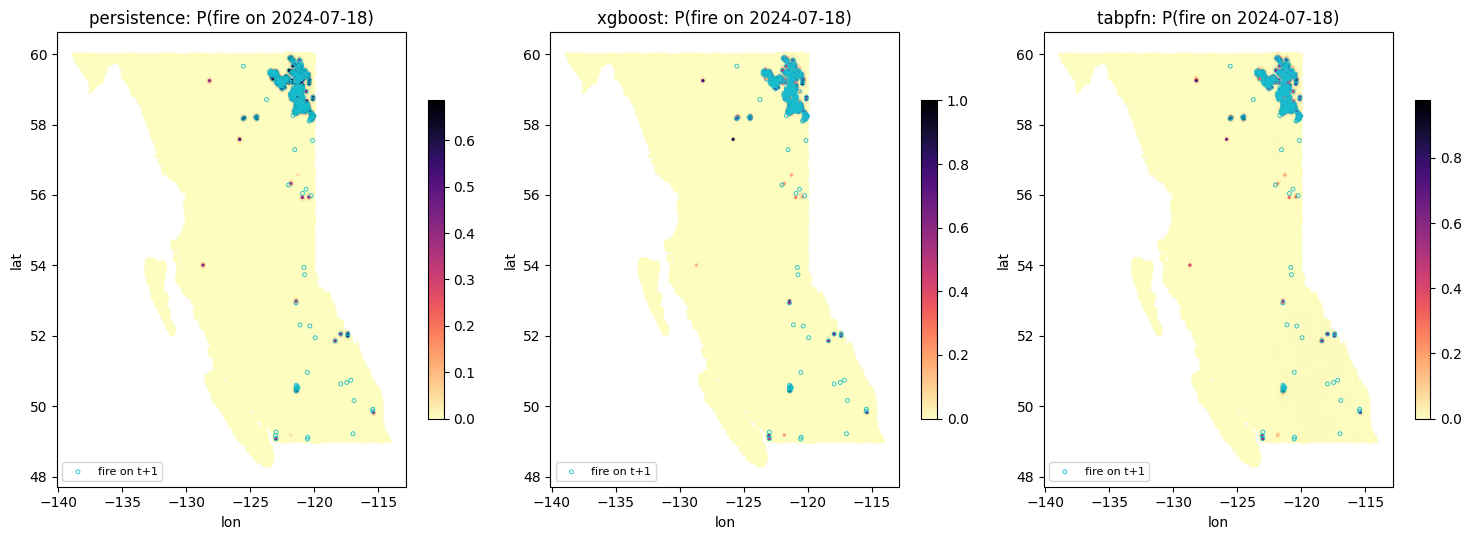

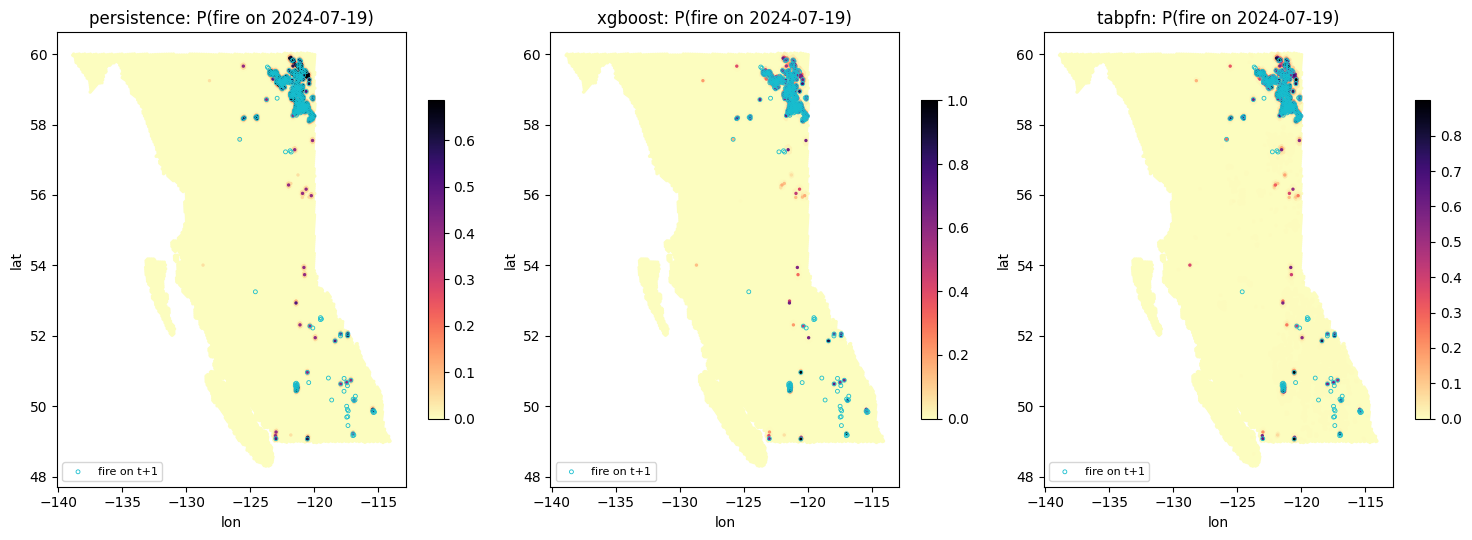

In [29]:
# Risk maps for the two 2024 days with the most fire the next day.
map_pd = parts["map"].select("h3_cell", "date", "h3_lat", "h3_lon", "y").to_pandas()
models = [m for m in ("persistence", "xgboost", "tabpfn") if m in PRED and PRED[m]["map"] is not None]
for day in MAP_DATES:
    sel = (map_pd["date"] == pd.Timestamp(day)).to_numpy()
    fig, axes = plt.subplots(1, len(models), figsize=(5 * len(models), 5.5), squeeze=False)
    for ax, model in zip(axes[0], models):
        p = PRED[model]["map"][sel]
        order = np.argsort(p)
        sc = ax.scatter(map_pd.loc[sel, "h3_lon"].to_numpy()[order], map_pd.loc[sel, "h3_lat"].to_numpy()[order],
                        c=p[order], s=2, cmap="magma_r", vmin=0, vmax=max(float(p.max()), 1e-6))
        fire = sel & (map_pd["y"].to_numpy() == 1)
        ax.scatter(map_pd.loc[fire, "h3_lon"], map_pd.loc[fire, "h3_lat"], s=8, facecolors="none",
                   edgecolors="tab:cyan", linewidths=0.6, label="fire on t+1")
        ax.set(title=f"{model}: P(fire on {day + dt.timedelta(days=1)})", xlabel="lon", ylabel="lat")
        ax.legend(loc="lower left", fontsize=8)
        fig.colorbar(sc, ax=ax, shrink=0.7)
    plt.tight_layout()
    plt.savefig(OUT_DIR / f"risk_map_{day}.png", dpi=150)
    plt.show()

In [30]:
# Save 2024 test predictions (sampled rows with their weights) for later analysis.
test_out = parts["test"].select("h3_cell", "date", "y", "weight", "active").to_pandas()
for model, preds in PRED.items():
    test_out[f"p_{model}"] = preds["test"]
test_out.to_parquet(OUT_DIR / "test_2024_predictions.parquet", index=False)
print("Saved to", OUT_DIR)

Saved to /content/drive/MyDrive/content/tabpfn_next_day_outputs


## Reading the results

- **Compare against persistence first.** Most next-day fire is in cells already burning or next to one, so persistence is strong. A model is useful only if it beats it on PR-AUC.
- **Active vs quiet rows.** The sanity-check cell prints what share of 2023 positives were new ignitions with no recent fire nearby. Those are the hardest cases: weather alone, at ERA5 resolution, can only raise the regional risk.
- **2023 vs 2024.** 2023 was an extreme season (about 21k fire cell-days compared with 9k in 2024), so thresholds tuned on 2023 may not transfer perfectly. Report both.

**Ideas for next steps:**
- Add ERA5 weather for day *t+1* as a stand-in for a weather forecast (in real use, you'd use a forecast).
- Add the Canadian Fire Weather Index (FFMC, DMC, DC, ISI, BUI, FWI) computed from ERA5.
- Add static layers: fuel type, land cover, distance to roads and settlements.
- Predict fire within the next 3 days instead of the next day.